# 01 — Exploratory data analysis of the lead funnel

**Question:** what is normal and what is unusual in how leads are handled, and what can — and cannot — this data tell us before any inference (F08)?

This notebook is deliberately *thin*: every computation lives in [`src/lead_funnel/analysis/eda.py`](../src/lead_funnel/analysis/eda.py), which is unit-tested. The notebook only calls those functions and shows the results.

**Run:** `python scripts/run_notebooks.py` from the repository root, after `lead-funnel generate`, `lead-funnel ingest` and `dbt build`.

**Scope:** one row per lead from `marts.fct_leads`; probable duplicates excluded (known issue KI-01). Committed outputs: seed 42, 50 000 leads.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from lead_funnel.analysis import eda
from lead_funnel.config import get_settings
from lead_funnel.ingestion.warehouse import connect

pd.set_option("display.precision", 3)
settings = get_settings()
FIGURES = settings.reports_dir / "figures"

with connect(settings.db_path, read_only=True) as con:
    leads = eda.load_leads(con)
print(f"{len(leads):,} leads, {leads.shape[1]} variables")

50,000 leads, 27 variables


## 1. Variables: measurement level and role

The measurement level decides which statistics and charts are valid: a mean of a nominal code is meaningless, a cumulative share only makes sense for ordered categories, and `local_hour` is *cyclic* (23 h is next to 0 h).

In [2]:
eda.variable_catalog(leads)

,variable,level,role,dtype,pct_missing,distinct,description
0,lead_id,identifier,id,str,0.00,50000,CRM key; no analytical meaning
1,created_at_local,datetime,time,datetime64[us],0.00,49902,"creation time, local"
2,local_hour,discrete,time,int64,0.00,24,hour of creation 0-23 (cyclic)
3,iso_year,discrete,time,int64,0.00,2,ISO week-numbering year
4,iso_week,discrete,time,int64,0.00,52,ISO week 1-53
5,iso_day_of_week,ordinal,time,int64,0.00,7,1 = Monday … 7 = Sunday
6,channel,nominal,dimension,str,0.00,4,how the lead arrived
7,lead_source,nominal,dimension,str,0.00,6,marketing source
8,agent_id,nominal,dimension,str,0.00,40,owning agent
9,team,nominal,dimension,str,0.00,4,owner's team at creation


## 2. Distributions

Classical statistics next to robust ones. For a skewed variable the mean and the standard deviation describe the tail, not the typical case.

In [3]:
pd.DataFrame(
    {
        "response time (min)": eda.describe_numeric(eda.valid_response_minutes(leads)),
        "lead score": eda.describe_numeric(leads["lead_score"]),
        "company size (employees)": eda.describe_numeric(leads["company_size"]),
    }
).round(2)

,response time (min),lead score,company size (employees)
n,47743.00,50000.00,43083.00
missing,0.00,0.00,6917.00
mean,477.22,50.34,212.56
median,77.20,50.00,79.00
mode,4.73,50.00,16.00
std,3058.58,15.72,523.44
iqr,213.63,21.00,173.00
mad,61.22,11.00,59.00
min,0.33,0.00,1.00
p05,6.65,24.00,8.00


In [4]:
eda.frequency_table(leads["company_size_band"], eda.ORDINAL_ORDER["company_size_band"])

,n,pct,cum_pct
company_size_band,,,
small,15868,0.317,0.317
medium,18273,0.365,0.683
large,7397,0.148,0.831
enterprise,1545,0.031,0.862
unknown,6917,0.138,1.000


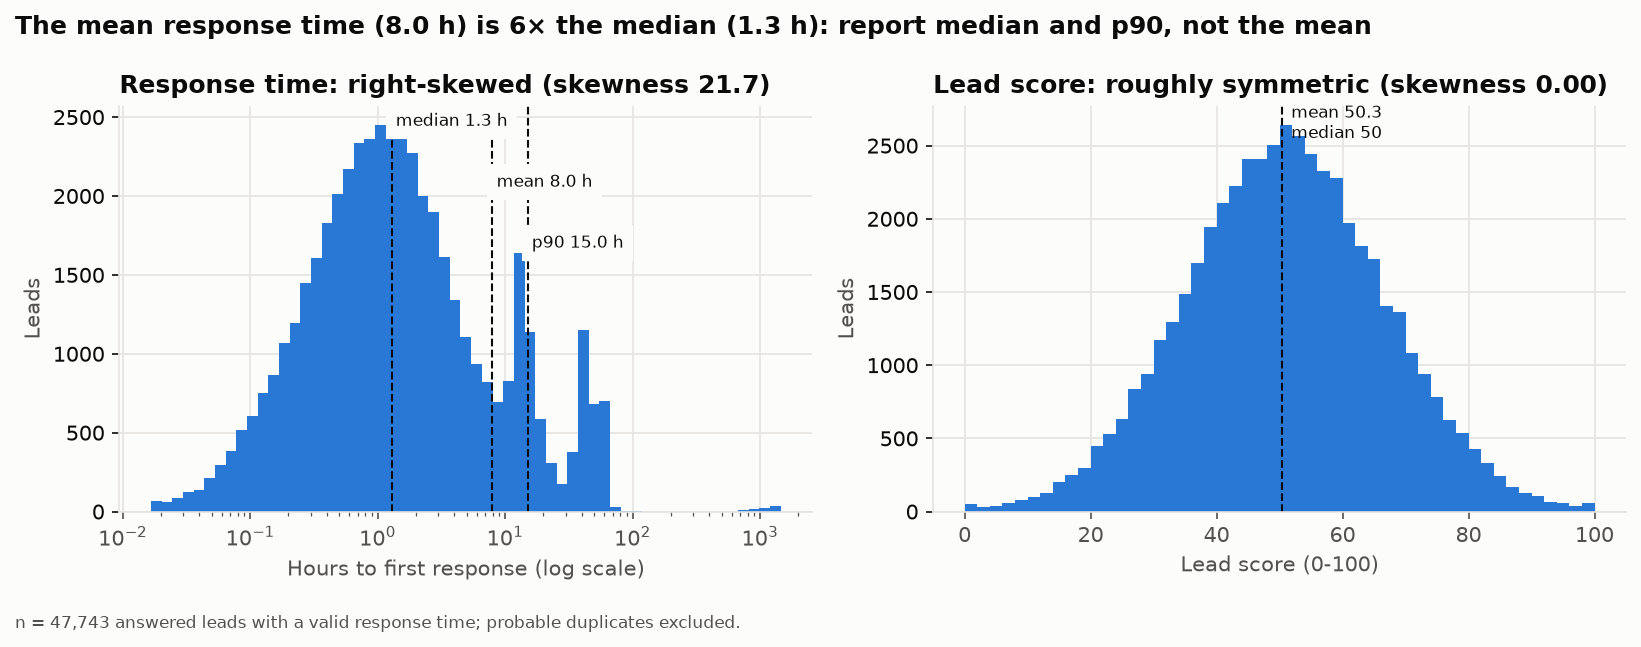

In [5]:
display(Image(eda.plot_distributions(leads, FIGURES / "eda_distributions.png")))

**Reading:** response time is heavily right-skewed and *multimodal* — a main mode around one hour and secondary peaks for leads created at night or at weekends, who wait for the next opening. Report the **median and p90**, never the mean. Lead score is roughly symmetric, so mean and median agree.

## 3. Groups

Every rate comes with its group size and a 95 % Wilson interval: a rate on a small group is a weak signal.

In [6]:
eda.compare_groups(leads, "channel")[
    ["n", "conversion_rate", "conversion_lo", "conversion_hi", "sla_rate", "median_response_h"]
]

,n,conversion_rate,conversion_lo,conversion_hi,sla_rate,median_response_h
channel,,,,,,
web_form,24593,0.126,0.122,0.130,0.369,1.421
phone,11030,0.167,0.160,0.174,0.711,0.307
email,8999,0.111,0.105,0.118,0.182,2.701
partner_referral,5378,0.346,0.333,0.359,0.416,1.249


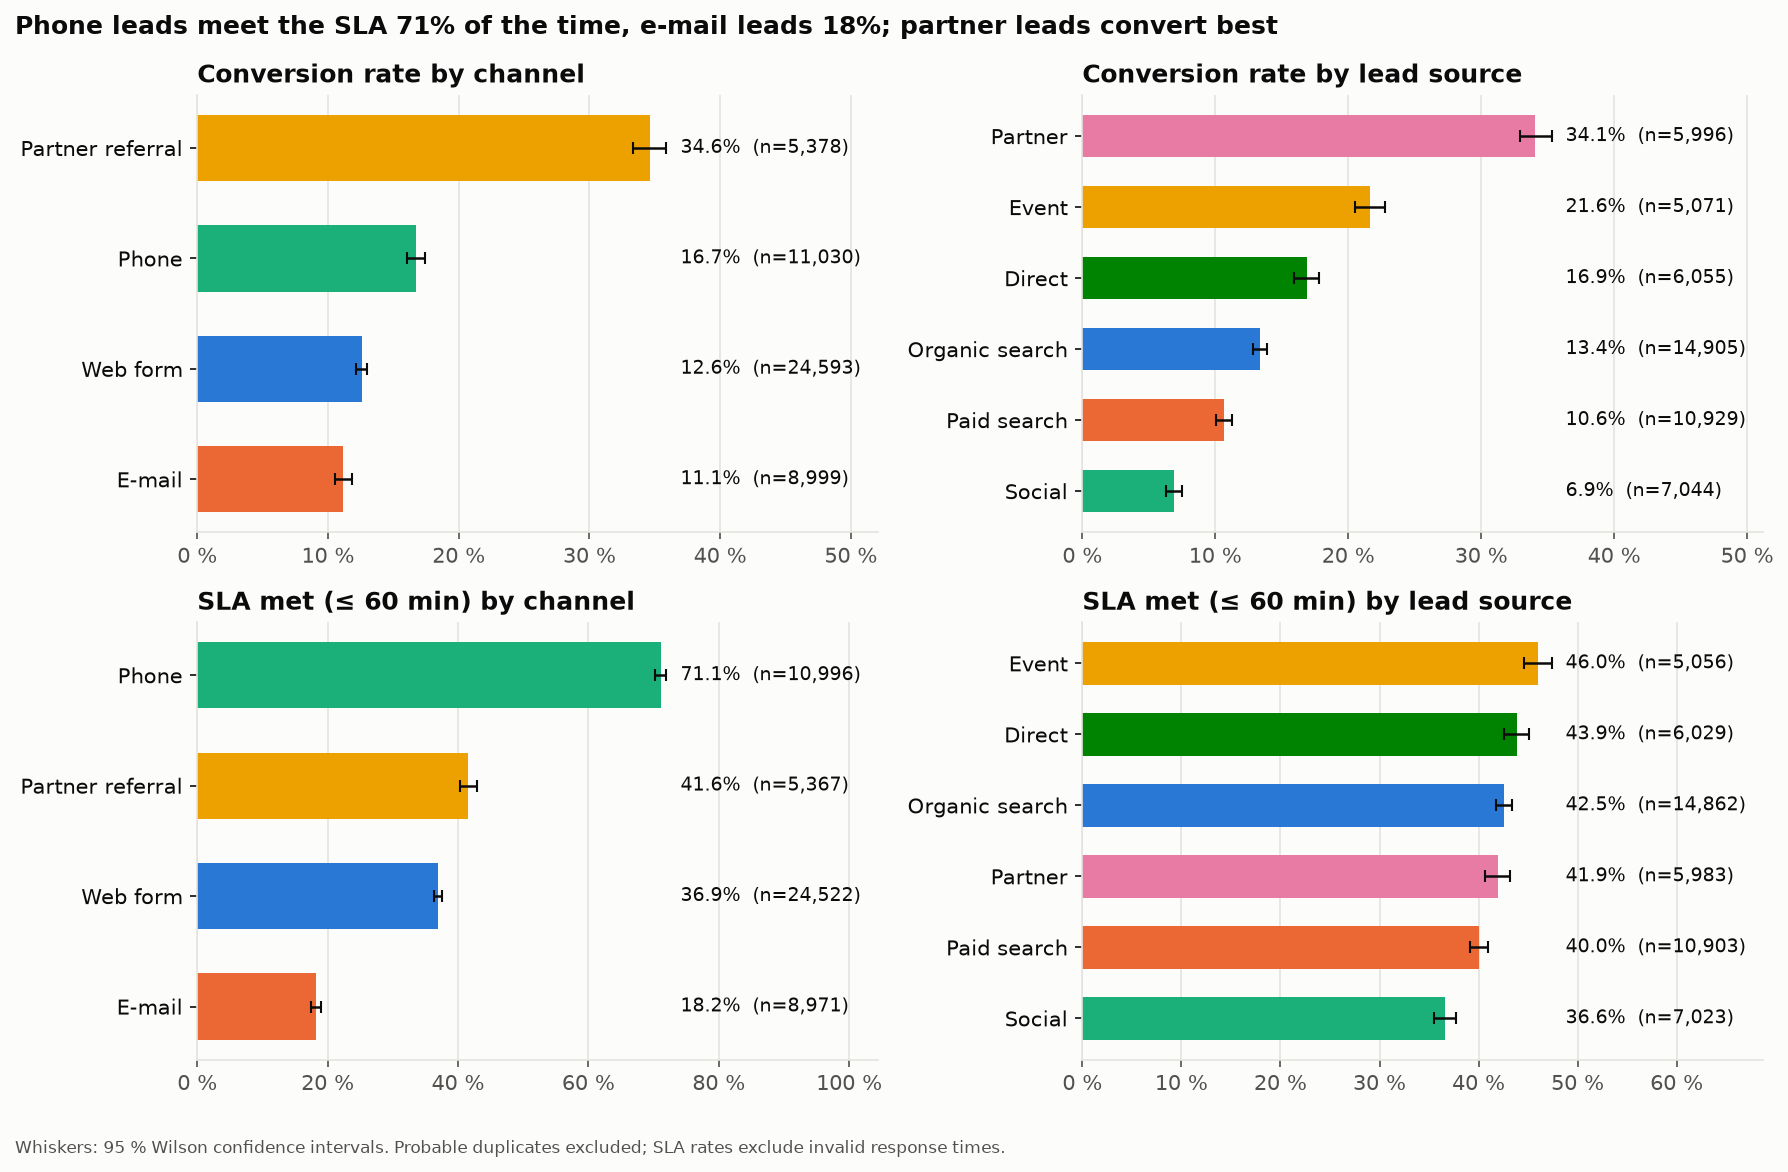

In [7]:
display(Image(eda.plot_group_comparison(leads, FIGURES / "eda_groups.png")))

Agents who changed team during the year — the same person before and after, thanks to the point-in-time (SCD type 2) team on every lead:

In [8]:
eda.team_change_comparison(leads)

,agent_id,team,leads,sla_rate,period
0,A012,inbound_dach,853,0.367,before
1,A012,inbound_international,552,0.336,after
2,A032,partner,554,0.321,before
3,A032,inbound_dach,722,0.351,after
4,A038,enterprise,115,0.504,before
5,A038,partner,362,0.457,after
6,A040,enterprise,100,0.41,before
7,A040,partner,344,0.387,after


**Reading:** channel strongly separates both speed and outcome — phone leads are answered fastest, e-mail leads slowest; partner leads convert best. These group differences are *descriptive*: channel and source also differ in lead quality, so they cannot be read as effects (see section 6, L2).

## 4. Periods

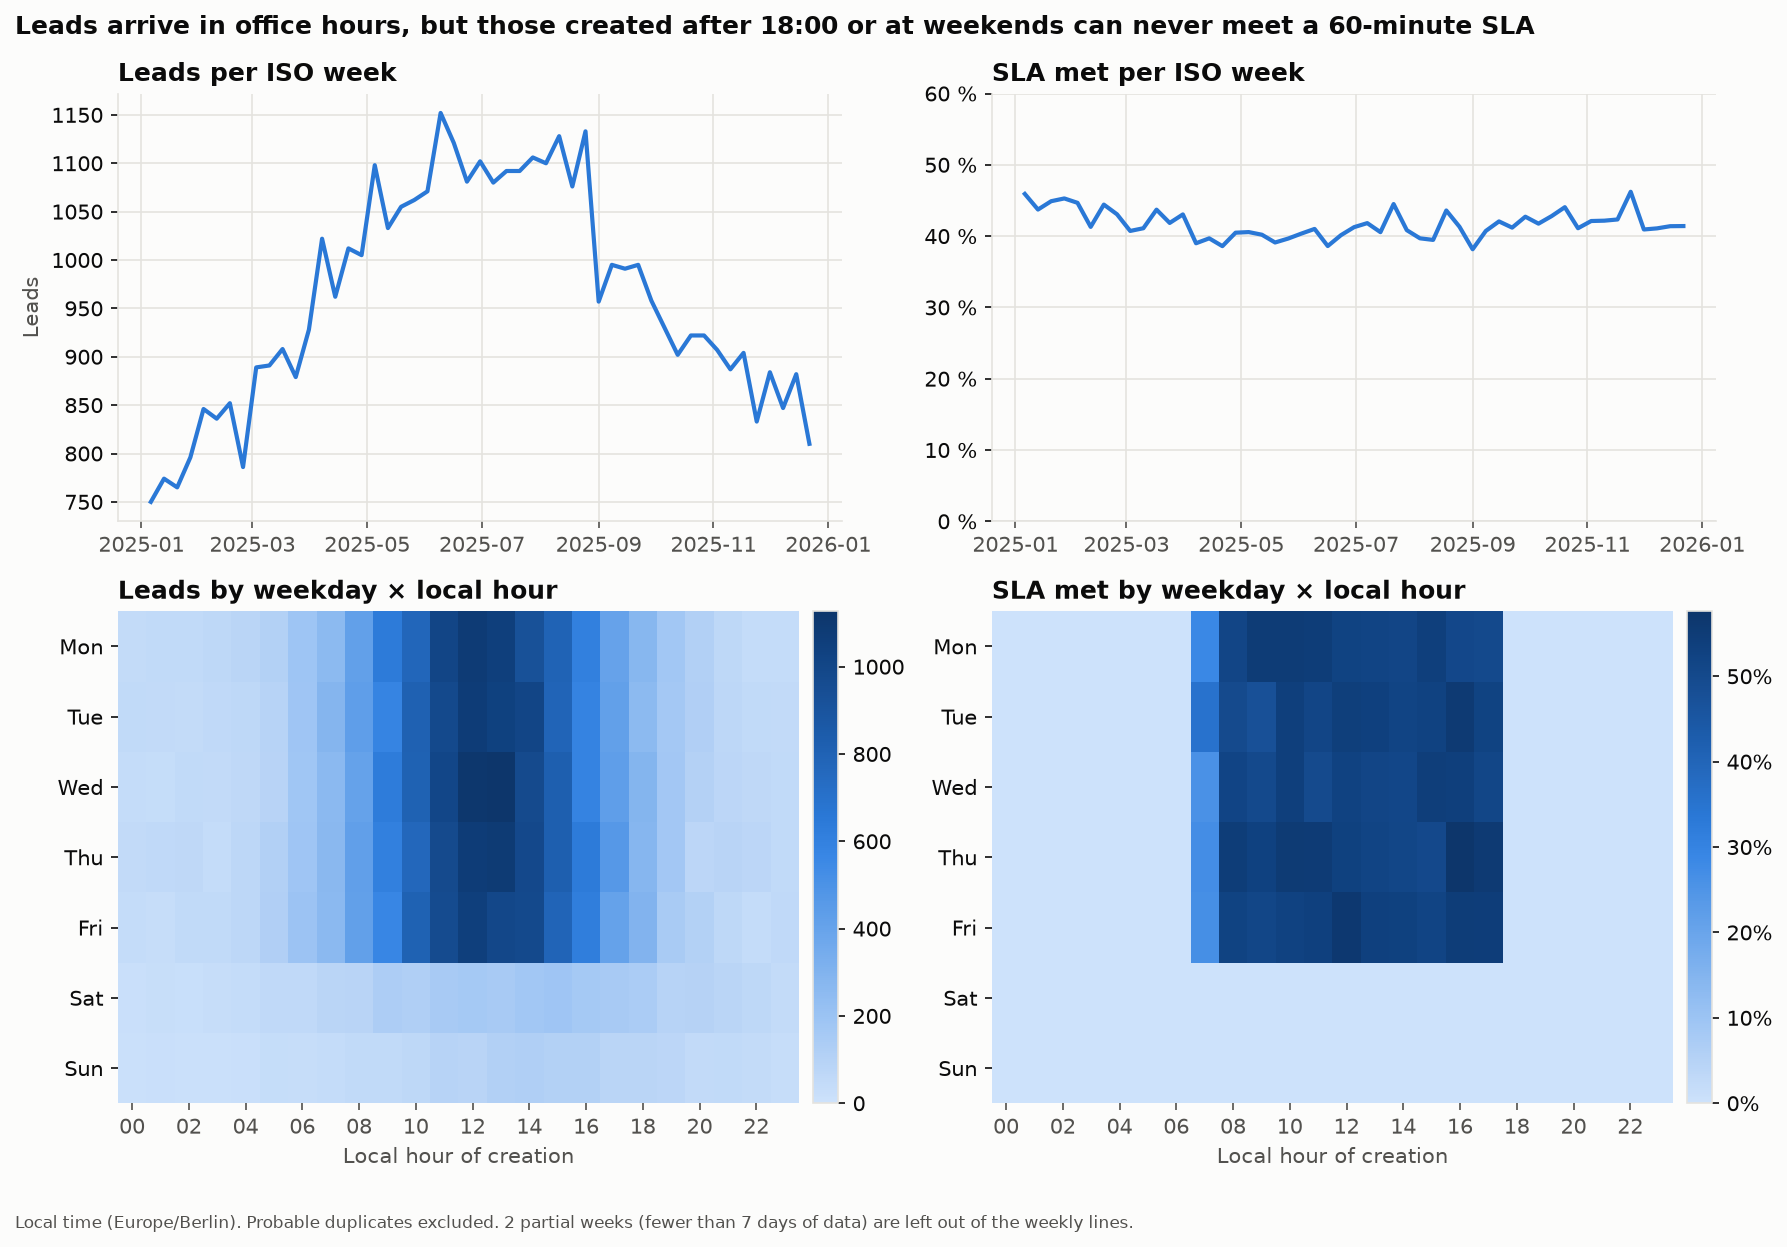

In [9]:
display(Image(eda.plot_periods(leads, FIGURES / "eda_periods.png")))

**Reading:** volume follows a seasonal curve, while the weekly SLA rate stays flat around 40-45 % — workload alone does not explain missed SLAs. The heatmaps show why: leads created outside Mon-Fri 08:00-18:00 *cannot* be answered within 60 minutes. Partial ISO weeks at the edges of the data are left out of the lines.

## 5. Anomalies and missing values

An outlier is a statistical statement; an error is a domain statement. Rules built for symmetric data misfire on skewed data.

In [10]:
eda.outlier_method_comparison(eda.valid_response_minutes(leads))

,rule,flagged,share
0,IQR fence on raw minutes,7822,0.164
1,IQR fence on log10(minutes),96,0.002
2,robust z > 3.5 on log10(minutes),95,0.002
3,domain rule: > 30 days,95,0.002


In [11]:
eda.classify_response_times(leads).value_counts()

response_time_class
normal                     44695
extreme but plausible       2953
impossible (negative)        144
implausible (> 30 days)       95
Name: count, dtype: int64

Because the data is synthetic, the generator's injection log tells us which errors are real — so the detection rules can be evaluated (impossible with real data):

In [12]:
truth_file = settings.raw_dir / "_ground_truth.json"
if truth_file.exists():
    injected = json.loads(truth_file.read_text(encoding="utf-8"))["injected_issues"]
    display(eda.detection_vs_injected(leads, injected))

,flag,flagged,injected,precision,recall
0,is_response_time_invalid,144,144,1.0,1.0
1,is_response_time_outlier,95,95,1.0,1.0


In [13]:
display(eda.missingness_by(leads, "company_size", "channel"))
display(eda.missingness_by(leads, "industry", "channel"))

,n,missing,share,lo,hi
channel,,,,,
web_form,24593,6153,0.25,0.245,0.256
partner_referral,5378,166,0.031,0.027,0.036
phone,11030,335,0.03,0.027,0.034
email,8999,263,0.029,0.026,0.033


,n,missing,share,lo,hi
channel,,,,,
email,8999,773,0.086,0.080,0.092
web_form,24593,1959,0.080,0.076,0.083
phone,11030,868,0.079,0.074,0.084
partner_referral,5378,406,0.075,0.069,0.083


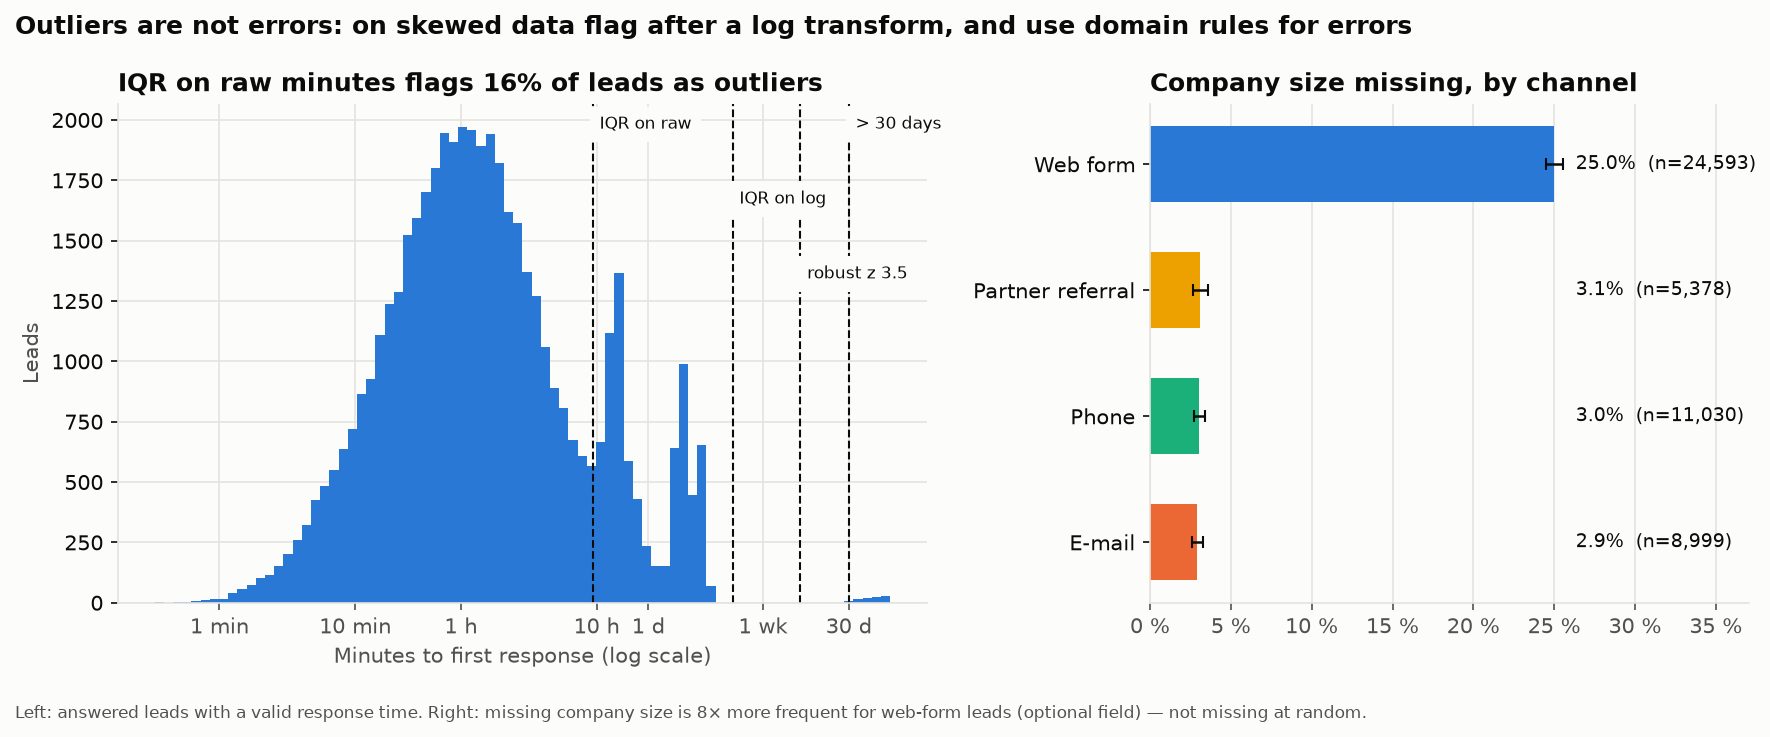

In [14]:
display(Image(eda.plot_anomalies(leads, FIGURES / "eda_anomalies.png")))

**Reading:** the IQR fence on raw minutes would discard a large share of legitimate night and weekend waits; on the log scale, and with the domain rule "> 30 days", only the genuine data errors remain. `company_size` is missing far more often for web-form leads (an optional field): not missing at random, so dropping those rows would bias any model towards other channels. `industry` is missing evenly — consistent with MCAR.

## 6. Limitations of the source

Full list with consequences: [`docs/data/known_issues.md`](../docs/data/known_issues.md#limitations-of-the-source-what-the-data-cannot-tell-us).

- **L1 Selection** — only leads that reached the CRM exist.
- **L2 Confounding** — agents choose whom to answer first (high-score leads), so fast and slow leads differ before any effect of speed.
- **L3 Measurement error** on response time (clock skew, wrong import dates).
- **L4 Non-random missingness** — company size missing mostly for web forms.
- **L5 External validity** — one year, one organisation.
- **L6 Process structure** — no SLA possible outside business hours.
- **L7 Unobserved drivers** — budget, urgency, contact role are not recorded.

## Takeaways for the inference step (F08)

1. Compare SLA-met vs missed leads only **after adjusting** for lead score, channel and source — the groups differ in quality before speed matters.
2. Use valid response times; treat flagged errors explicitly (exclude + robustness check).
3. Keep an `unknown` company-size category instead of dropping rows.
4. Business-hours leads are the population where the SLA is actually actionable.